# Hyperparameter - Trajectory Relationship (ST)
This simulation is intended to demonstrate the impacts of environmental hyperparameters on the ergodic trajectories generated.

In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Documents/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra

In [5]:
# Import modules
include("../../src/jordan_lake_domain.jl")
include("../../src/stgpkf.jl")
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/ergodic.jl")
include("../../src/variograms.jl")
include("../../src/SOC_Controller.jl")
include("../../src/simulator_spatial.jl")
include("../../src/simulator_ST.jl")
include("../../src/Convex_bound_avoidance.jl")

Main.ConvexBoundAvoidance

In [6]:
# Define domain vars
sdim = 10; # number of data points along each axis in the domain (defining a square domain)
tdim = 100; # number of temporal data points
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions
tstart, tstop = 0, 3; # start and end times

σ_sq = 1.0; # variance
λₓ = 1/30.0; # spatial length scale
λₜ = 0.001; # temporal length scale

env_data = SyntheticData.matern12_spatiotemporal(sdim, tdim, xstart, xstop, ystart, ystop, tstart, tstop, σ_sq, λₓ, λₜ);

In [7]:
env_data.T

100-element Vector{Float64}:
   0.0
   1.8181818181818181
   3.6363636363636362
   5.454545454545454
   7.2727272727272725
   9.090909090909092
  10.909090909090908
  12.727272727272727
  14.545454545454545
  16.363636363636363
   ⋮
 165.45454545454547
 167.27272727272728
 169.0909090909091
 170.9090909090909
 172.72727272727272
 174.54545454545453
 176.36363636363637
 178.1818181818182
 180.0

In [8]:
plotly();
t_ind = 1
heatmap(env_data.X, env_data.Y, env_data.W[:, :, t_ind]', cmap = :balance; plottype=:wx)
plot!(clims=(-2,2))

┌ Warning: Failed to load integration with PlotlyBase & PlotlyKaleido.
│   exception =
│    ArgumentError: Package PlotlyBase not found in current path.
│    - Run `import Pkg; Pkg.add("PlotlyBase")` to install the PlotlyBase package.
│    Stacktrace:
│      [1] macro expansion
│        @ ./loading.jl:1772 [inlined]
│      [2] macro expansion
│        @ ./lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1753
│      [4] #invoke_in_world#3
│        @ ./essentials.jl:926 [inlined]
│      [5] invoke_in_world
│        @ ./essentials.jl:923 [inlined]
│      [6] require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1746
│      [7] top-level scope
│        @ ~/.julia/packages/Plots/du2dt/src/backends.jl:568
│      [8] eval
│        @ ./boot.jl:385 [inlined]
│      [9] _initialize_backend(pkg::Plots.PlotlyBackend)
│        @ Plots ~/.julia/packages/Plots/du2dt/src/backends.jl:567
│     [10] backend
│        @ ~/.julia/packages/Plots/du

[ Info: Saved animation to /tmp/jl_2ZQzIbC16H.gif


Plots.AnimatedGif("/tmp/jl_2ZQzIbC16H.gif")
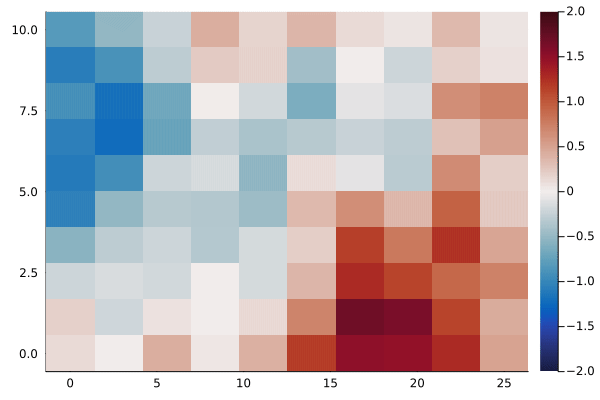

In [9]:
gr()
@gif for i=1:size(env_data.W,3)
    data = heatmap(env_data.X, env_data.Y, env_data.W[:, :, i]', cmap = :balance; plottype=:wx)
    plot(data)
    plot!(clims=(-2,2))
end

In [14]:
# Create an ngpkf grid based on the data
σ_spatial = σ_sq
l_spatial = 1/λₓ

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )



# ngp_grid_x = range(extrema(env_data.X)..., length=10) # step= res_factor )
# ngp_grid_y = range(extrema(env_data.Y)..., length=10)# step= res_factor )

0.0:0.4:10.0

In [15]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 30.0), [60.0150111040239 -32.3237657731039 … 0.0012269775072304696 0.006209722496648155; -32.3237657731039 84.27596361072308 … 0.000266250817424138 0.0012269775072685347; … ; 0.0012269775072304696 0.000266250817424138 … 84.27596361072952 -32.32376577310318; 0.006209722496648155 0.0012269775072685347 … -32.32376577310318 60.015011104021234])

In [16]:
size(ngp_grid_x), size(ngp_grid_y)

((63,), (26,))

In [17]:
@assert maximum(abs.(ngpkf_grid.invK)) < 10.0


AssertionError: AssertionError: maximum(abs.(ngpkf_grid.invK)) < 10.0

In [18]:
maximum(abs.(ngpkf_grid.invK))


97.29276775349473

In [19]:
size(ngpkf_grid.invK')

σ_t = zeros(size(env_data.W, 1), size(env_data.W, 2));

In [20]:
for i in CartesianIndices(σ_t)
    σ_t[i] = Variograms.estimate_σt(env_data.T, env_data.W[i[1], i[2], :])
end

UndefVarError: UndefVarError: `estimate_σt` not defined

In [21]:
# Create the interpolation object with linear interpolation
itp_σ_t  = linear_interpolation((env_data.X,env_data.Y), σ_t)


10×10 extrapolate(interpolate((::Vector{Float64},::Vector{Float64}), ::Matrix{Float64}, Gridded(Linear())), Throw()) with element type Float64:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0

In [22]:
# xscale = size(σ_t, 1)/size(ngp_grid_x, 1)
# yscale = size(σ_t, 2)/size(ngp_grid_y, 1)

xscale = range(1, 10, 63)
yscale = range(1, 10, 26)
# yscale = size(σ_t, 2)/size(ngp_grid_y, 1)

1.0:0.36:10.0

In [23]:
σ_t_scaled = itp_σ_t[xscale, yscale]

63×26 Matrix{Float64}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 ⋮                        ⋮              ⋱       ⋮                        ⋮
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  … 

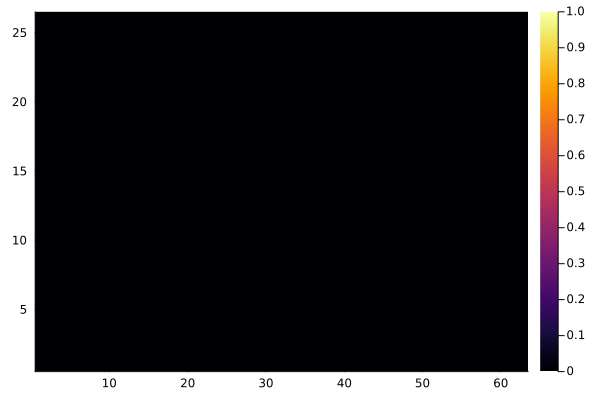

In [25]:
heatmap(σ_t_scaled')

In [28]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [5.2, 8.4]

In [29]:
SimulatorST.measure(0.0, x0s, env_data; σ_meas = 0.05)

ps: SVector{2, Float64}[[5.2, 8.4]]


1-element Vector{Main.SimulatorST.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}:
 Main.SimulatorST.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}(0.0, [5.2, 8.4], -0.5386985154910875)

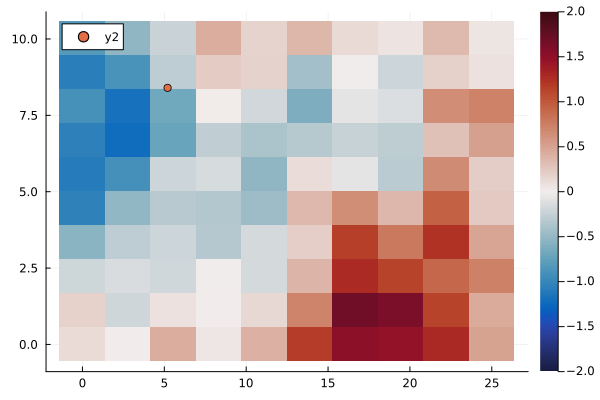

In [30]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W[:, :, t_ind]', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s))
plot!(clims=(-2,2))

In [31]:
ΔT = 5.0 / 60.0 # seconds
Tend = 1.0 # hours 
ts = 0.0:(ΔT):(Tend * 60)

0.0:0.08333333333333333:60.0

In [32]:
function ergoControllers(t, xs; 
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
    
    # target_spatial_dist = 1 .- ergo_q_map; 
    target_spatial_dist = ones(size(ergo_q_map));
    
    # @show t
    ck_minus_Mk = ErgodicController.ckMk(ergo_grid, traj, target_spatial_dist)

    us = [ErgodicController.controller_single_integrator(ergo_grid, x, ck_minus_Mk; umax=umax) for x in xs]
    return us
end

ergoControllers (generic function with 1 method)

In [33]:
env_data(9.0, 7.0, 4.0)

0.33071365747218096

In [35]:
ΔT = 5.0/60.0 # minutes
Tend = 2.0 # hours 
ts = 0.0:(ΔT):(Tend * 60)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes

0.08333333333333333

In [36]:
@time res_ergo =  SimulatorST.simulate_spatial(ts, x0s, ergoControllers; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataST=env_data, 
    σ_meas = 0.5,
    Q_process = diagm(vec(σ_t_scaled .^2 * fuse_measurements_every_ΔT )) , 
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT,
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

going into measurements
ps: SVector{2, Float64}[[5.2, 8.4]]
going out of measurements
ps: SVector{2, Float64}[[5.2, 8.4]]


Progress:   0%|                                         |  ETA: N/A


ps: SVector{2, Float64}[[5.349169622196166, 8.41576146610735]]
ps: SVector{2, Float64}[[5.498947262054121, 8.423925937834342]]
ps: SVector{2, Float64}[[5.648944664843189, 8.423043239395458]]
ps: SVector{2, Float64}[[5.798048804868089, 8.4066738952597]]
ps: SVector{2, Float64}[[5.944519226428861, 8.374325547422297]]
ps: SVector{2, Float64}[[6.0841439038037475, 8.319508128037954]]
ps: SVector{2, Float64}[[6.214138529530234, 8.244665644900163]]
ps: SVector{2, Float64}[[6.334103236064436, 8.154618606158389]]
ps: SVector{2, Float64}[[6.44417925072899, 8.052720269589193]]
ps: SVector{2, Float64}[[6.546207318322304, 7.9427644901905]]
ps: SVector{2, Float64}[[6.642290715862536, 7.827577769093294]]


Progress:   1%|▎                                        |  ETA: 0:05:32


ps: SVector{2, Float64}[[6.733820849012482, 7.708740760019718]]
ps: SVector{2, Float64}[[6.82148027727148, 7.587020487931189]]
ps: SVector{2, Float64}[[6.9054661966312505, 7.462737080553961]]
ps: SVector{2, Float64}[[6.985475604682845, 7.33585723730361]]
ps: SVector{2, Float64}[[7.067035992336755, 7.209968782051574]]
ps: SVector{2, Float64}[[7.14806871793277, 7.083740031830078]]
ps: SVector{2, Float64}[[7.228710697808701, 6.957261294163662]]
ps: SVector{2, Float64}[[7.307741446173897, 6.82976956575418]]
ps: SVector{2, Float64}[[7.384133453031319, 6.700679437207124]]
ps: SVector{2, Float64}[[7.462842724826044, 6.572988989116657]]
ps: SVector{2, Float64}[[7.542679225844705, 6.446000276606067]]
ps: SVector{2, Float64}[[7.622071520174998, 6.3187333775279]]


...

ps: SVector{2, Float64}[[2.6929713257146135, 0.3215170364523207]]
ps: SVector{2, Float64}[[2.8402979111421414, 0.294723950081294]]


Progress: 100%|█████████████████████████████████████████| Time: 0:00:34


 40.771991 seconds (9.60 M allocations: 11.172 GiB, 7.67% gc time, 24.17% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:00:34


Main.SimulatorST.SimResult{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorST.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:120.0, Vector{SVector{2, Float64}}[[[5.2, 8.4]], [[5.349169622196166, 8.41576146610735]], [[5.498947262054121, 8.423925937834342]], [[5.648944664843189, 8.423043239395458]], [[5.798048804868089, 8.4066738952597]], [[5.944519226428861, 8.374325547422297]], [[6.0841439038037475, 8.319508128037954]], [[6.214138529530234, 8.244665644900163]], [[6.334103236064436, 8.154618606158389]], [[6.44417925072899, 8.052720269589193]]  …  [[1.7547536666541173, 0.5911856943672613]], [[1.8696442100232327, 0.5419202198366562]], [[1.9939503709885493, 0.49676020151693484]], [[2.1252317201

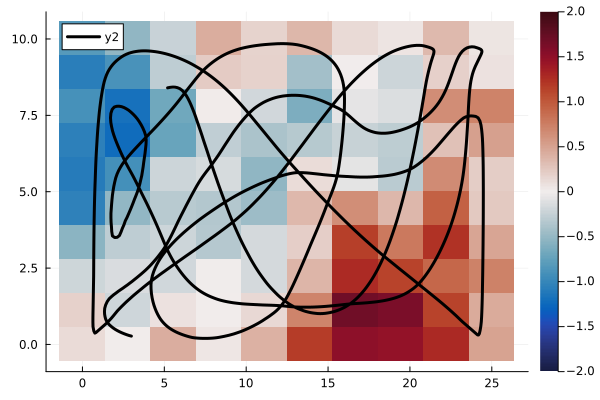

In [45]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W[:, :, t_ind]', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo.xs]
    y = [r[i][2] for r in res_ergo.xs]
    plot!(x, y, linewidth=3, color=:black)
end
plot!()
plot!(clims=(-2,2))

In [79]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W[:, :, 1]', cmap = :balance; plottype=:wx, clims=(-2,2))
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo.xs[1:n]]
        y = [r[i][2] for r in res_ergo.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

BoundsError: BoundsError: attempt to access 1-element Vector{SVector{2, Float64}} at index [2]

In [47]:
size(res_ergo.w_hats)

(24,)

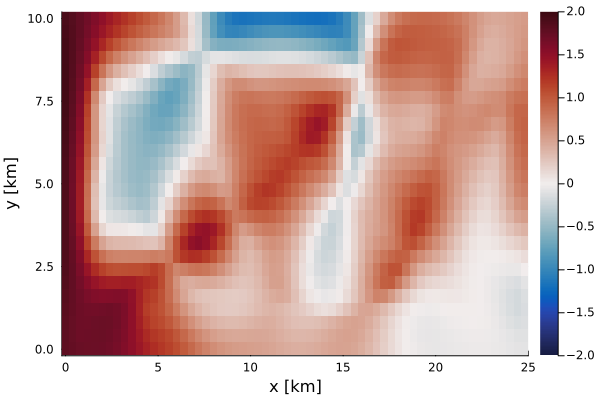

In [48]:
gr()

# heatmap(env_data.X, env_data.Y, env_data.W[:, :, t_ind]', cmap = :balance; plottype=:wx)

p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2))


[ Info: Saved animation to /tmp/jl_QVSpQ1KTm1.gif


Plots.AnimatedGif("/tmp/jl_QVSpQ1KTm1.gif")
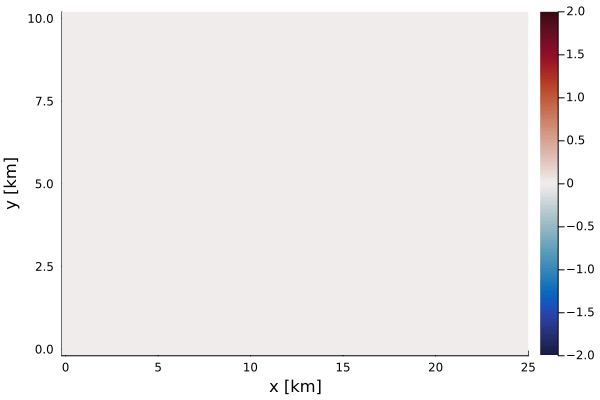

In [49]:
gr()
@gif for i=1:length(res_ergo.w_hats)
    p2 = heatmap(ngpkf_grid, res_ergo.w_hats[i], colormap=:balance, clims=(-2, 2))
    plot(p2)
end

[ Info: Saved animation to /tmp/jl_Sl4pgDw7Ep.gif


Plots.AnimatedGif("/tmp/jl_Sl4pgDw7Ep.gif")
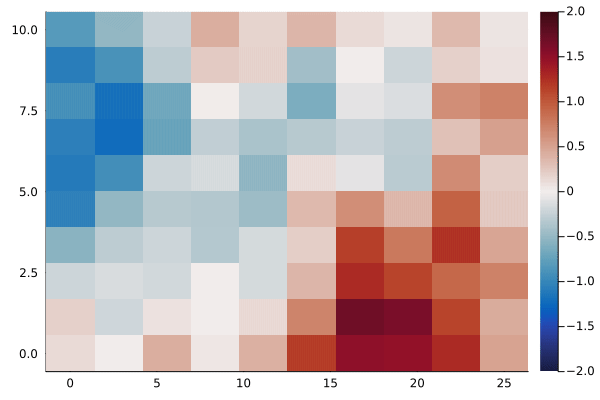

In [50]:
gr()
@gif for i=1:size(env_data.W,3)
    data = heatmap(env_data.X, env_data.Y, env_data.W[:, :, i]', cmap = :balance; plottype=:wx)
    plot(data)
    plot!(clims=(-2,2))
end

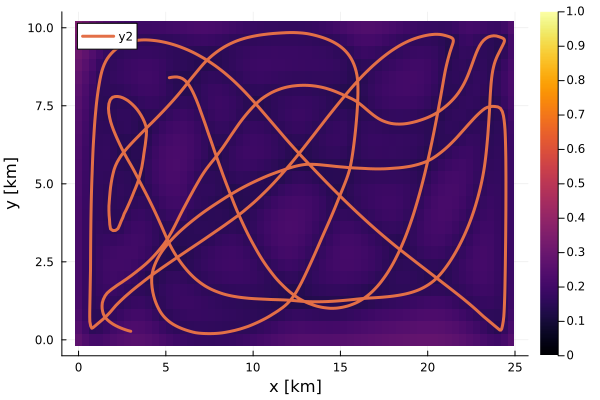

In [51]:
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end], clims=(0, 1.0), plotstd=true)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo.xs]
    y = [r[i][2] for r in res_ergo.xs]
    plot!(x, y, linewidth=3)
end
plot!()

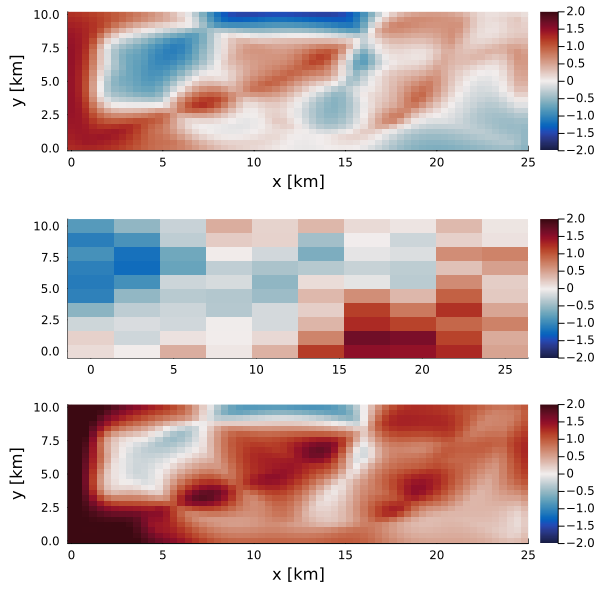

In [52]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W[:, :, t_ind]', cmap = :balance; plottype=:wx, clims=(-2,2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

In [55]:
# Given a variance and the spatial lengthscale make a kernel
σ_spatial = 1.0
l_spatial = 0.3
kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

Main.NGPKF.MaternKernel{Float64}(1.0, 0.3)

In [56]:
res_factor = 0.2 #l_spatial / sqrt(2.0)

0.2

In [57]:
range(0,10, step= 0.2)

0.0:0.2:10.0

In [58]:
ngp_grid_x = range(xstart,xstop, step= 0.2)
ngp_grid_y = range(ystart,ystop, step= 0.2)

0.0:0.2:10.0

In [59]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.2:25.0, 0.0:0.2:10.0, SVector{2, Float64}[[0.0, 0.0], [0.2, 0.0], [0.4, 0.0], [0.6, 0.0], [0.8, 0.0], [1.0, 0.0], [1.2, 0.0], [1.4, 0.0], [1.6, 0.0], [1.8, 0.0]  …  [23.2, 10.0], [23.4, 10.0], [23.6, 10.0], [23.8, 10.0], [24.0, 10.0], [24.2, 10.0], [24.4, 10.0], [24.6, 10.0], [24.8, 10.0], [25.0, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 0.3), [1.6146138299002224 -0.5960713681916092 … -6.362470316684953e-40 2.1950478168881343e-40; -0.5960713681916092 1.8881765520841673 … 7.371126129028155e-40 -3.838097762346931e-40; … ; -6.362470316684953e-40 7.371126129028155e-40 … 1.888176552084172 -0.5960713681916117; 2.1950478168881343e-40 -3.838097762346931e-40 … -0.5960713681916117 1.6146138299002268])

In [60]:
size(ngp_grid_x), size(ngp_grid_y)


((126,), (51,))

In [61]:
@assert maximum(abs.(ngpkf_grid.invK)) < 10.0

In [62]:
maximum(abs.(ngpkf_grid.invK))

2.0892500734311126

In [63]:
size(ngpkf_grid.invK')


(6426, 6426)

In [64]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:10]


10-element Vector{SVector{2, Float64}}:
 [21.2, 6.4]
 [4.8, 7.8]
 [13.0, 8.8]
 [23.8, 6.4]
 [4.4, 6.4]
 [21.2, 7.0]
 [11.8, 7.8]
 [19.4, 2.8]
 [17.4, 6.8]
 [7.8, 9.0]